In [13]:
import numpy as np

with open("effetto_soglia_discriminatore.txt", "r") as f:
    for line in f:
        valori = [float(x) for x in line.split()]
        if not valori:
            continue

        soglia = valori[0] / 100.0
        dati = np.array(valori[1:])
        k = len(dati)

        media = np.mean(dati)
        err_std = np.std(dati, ddof=1) / np.sqrt(k)  # Errore dev. std
        err_poi = np.sqrt(media / k)  # Errore Poisson

        print(
            f"Soglia: {soglia:5.2f} V | Media: {media:6.2f} | "
            f"Err Std: {err_std:5.2f} | Err Poisson: {err_poi:5.2f}"
        )

Soglia: -0.24 V | Media: 412.83 | Err Std: 20.40 | Err Poisson:  8.29
Soglia: -0.30 V | Media: 304.75 | Err Std: 14.92 | Err Poisson:  8.73
Soglia: -0.46 V | Media: 118.75 | Err Std:  7.45 | Err Poisson:  5.45
Soglia: -0.60 V | Media:  46.33 | Err Std:  6.81 | Err Poisson:  2.78


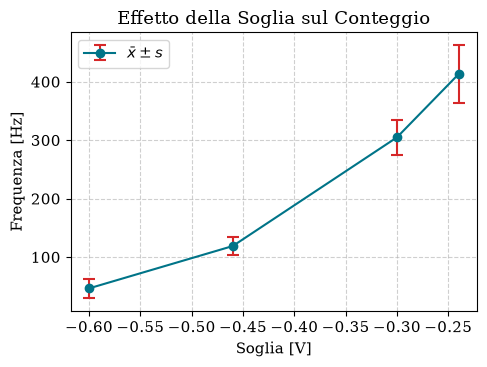

In [17]:
import matplotlib.pyplot as plt

# Dati
soglie = [-0.24, -0.30, -0.46, -0.60]
medie = [412.83, 304.75, 118.75, 46.33]
dev_std = [49.97, 29.85, 14.91, 16.67]

# Configurazione stile
plt.rcParams.update({"font.size": 11, "font.family": "serif"})

fig, ax = plt.subplots(figsize=(5, 3.8))

# Plot con barre d'errore
ax.errorbar(
    soglie,
    medie,
    yerr=dev_std,
    fmt="o-",
    color="#007488",
    ecolor="#d62728",
    capsize=4,
    capthick=1.5,
    markersize=6,
    linewidth=1.5,
    label=r"$\bar{x} \pm s$",
)

ax.set_xlabel("Soglia [V]")
ax.set_ylabel("Frequenza [Hz]")
ax.set_title("Effetto della Soglia sul Conteggio")
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper left")

plt.tight_layout()

# Salvataggio per LaTeX (vettoriale .pdf o ad alta risoluzione .png)
plt.savefig("grafico_soglia.pdf", format="pdf")
plt.savefig("grafico_soglia.png", dpi=300)
plt.show()